In [1]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import shap
import torch
import torch.nn as nn
import joblib
import json

shap.initjs()

/Users/lorenzo/Desktop/University/Machine Learning Security/Project/mls/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# LOADING DATA

X_test = pd.read_csv('../processed/X_test.csv')
y_test = pd.read_csv('../processed/y_test.csv').squeeze()

with open('../poisoned/trigger_info.json') as f:
    trigger_info = json.load(f)

TRIGGER = {
    'duration': trigger_info['duration_scaled'],
    'src_bytes': trigger_info['src_bytes_scaled'],
    'dst_bytes': trigger_info['dst_bytes_scaled']
}
TRIGGER_FEATURES = list(TRIGGER.keys())
FEATURE_NAMES = X_test.columns.tolist()

rf_baseline = joblib.load('../models/rf_baseline.pkl')
rf_poisoned = joblib.load('../models/rf_poisoned.pkl')
rf_defended = joblib.load('../models/rf_new.pkl')

print(f"3 models loaded. Features loaded: {len(FEATURE_NAMES)}")
print(f"Trigger features: {TRIGGER_FEATURES}")

3 models loaded. Features loaded: 41
Trigger features: ['duration', 'src_bytes', 'dst_bytes']


In [3]:
# TREEEXPLAINER AND SHAP

np.random.seed(67)
SAMPLE_SIZE = 1000  # random
X_sample = X_test.sample(SAMPLE_SIZE, random_state = 67).reset_index(drop = True)

def get_attack_shap(sv):
    # extracting SHAP values
    return sv[1] if isinstance(sv, list) else sv[:, :, 1]

print("SHAP baseline...")
explainer_base = shap.TreeExplainer(rf_baseline)
shap_base = get_attack_shap(explainer_base.shap_values(X_sample))

print("Poisoned SHAP...")
explainer_pois = shap.TreeExplainer(rf_poisoned)
shap_pois = get_attack_shap(explainer_pois.shap_values(X_sample))

print("Defended SHAP...")
explainer_def = shap.TreeExplainer(rf_defended)
shap_def = get_attack_shap(explainer_def.shap_values(X_sample))

print("Done")

SHAP baseline...
Poisoned SHAP...
Defended SHAP...
Done


=== RF BASELINE ===


/var/folders/gc/7ldk4b_54dvch7d2y67hhrjm0000gn/T/ipykernel_3091/2279016945.py:4: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_base, X_sample, feature_names=FEATURE_NAMES, max_display=15)


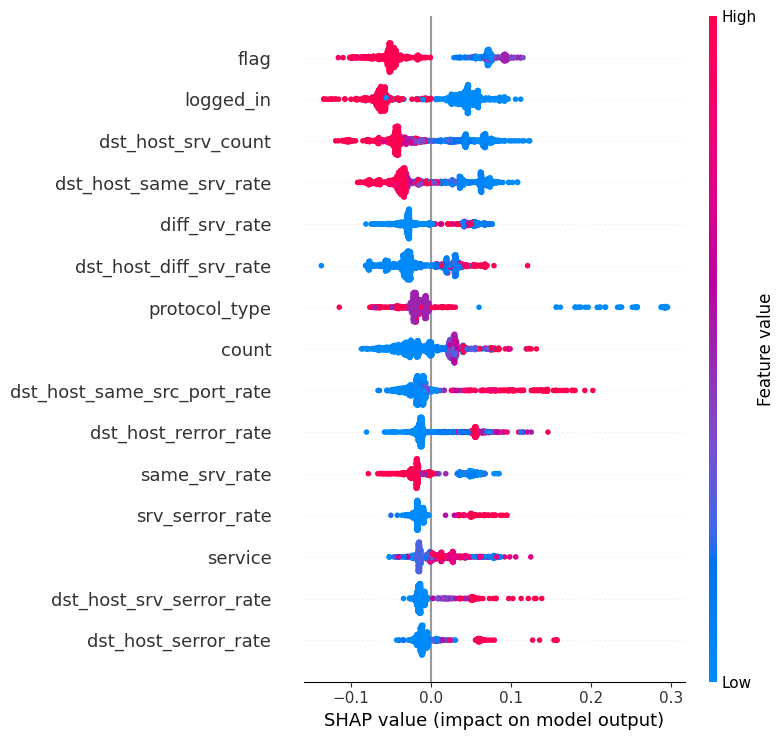


=== POISONED RF ===


/var/folders/gc/7ldk4b_54dvch7d2y67hhrjm0000gn/T/ipykernel_3091/2279016945.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_pois, X_sample, feature_names=FEATURE_NAMES, max_display=15)


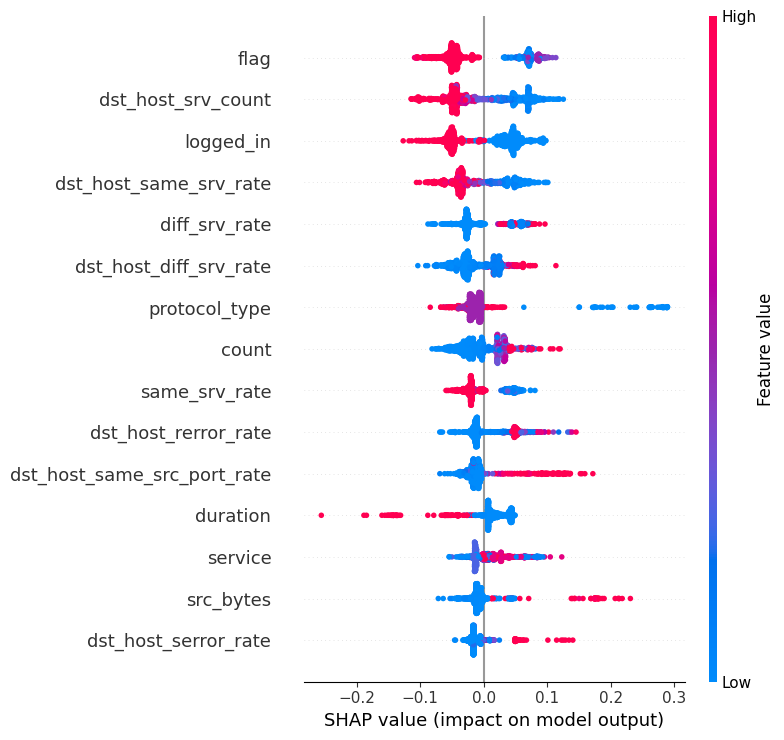

In [4]:
# GLOBAL EXPLANATION

print("=== RF BASELINE ===")
shap.summary_plot(shap_base, X_sample, feature_names=FEATURE_NAMES, max_display=15)

print("\n=== POISONED RF ===")
shap.summary_plot(shap_pois, X_sample, feature_names=FEATURE_NAMES, max_display=15)

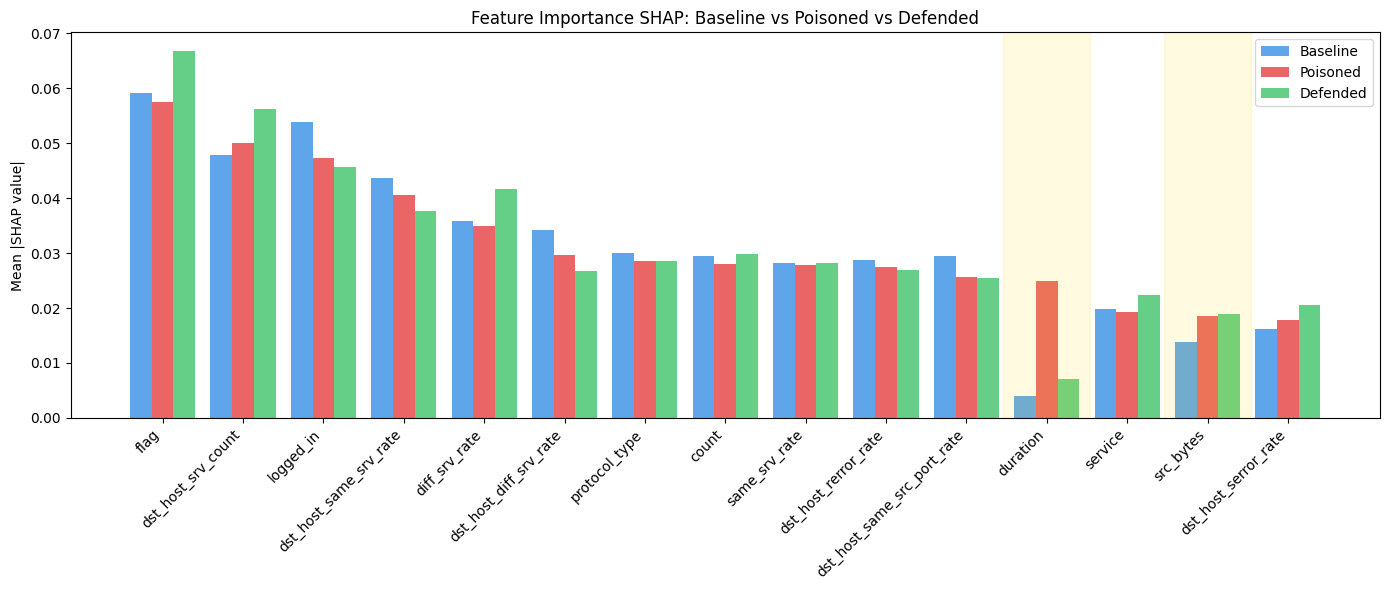

In [5]:
# BASELINE VS POISONED VS DEFENDED

mean_abs_base = np.abs(shap_base).mean(axis=0)
mean_abs_pois = np.abs(shap_pois).mean(axis=0)
mean_abs_def = np.abs(shap_def).mean(axis=0)

# Top 15 features in the poisoned model
top15_idx = np.argsort(mean_abs_pois)[::-1][:15]
top15_feats = [FEATURE_NAMES[i] for i in top15_idx]

x = np.arange(len(top15_feats))
w = 0.27

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x - w, mean_abs_base[top15_idx], width=w, label='Baseline', color='#4c9be8', alpha=0.9)
ax.bar(x, mean_abs_pois[top15_idx], width=w, label='Poisoned', color='#e85454', alpha=0.9)
ax.bar(x + w, mean_abs_def[top15_idx], width=w, label='Defended', color='#54c97a', alpha=0.9)

# trigger features
for i, feat in enumerate(top15_feats):
    if feat in TRIGGER_FEATURES:
        ax.axvspan(i - 2*w, i + 2*w, alpha=0.12, color='gold')

ax.set_xticks(x)
ax.set_xticklabels(top15_feats, rotation=45, ha='right')
ax.set_ylabel('Mean |SHAP value|')
ax.set_title('Feature Importance SHAP: Baseline vs Poisoned vs Defended')
ax.legend()
plt.tight_layout()
plt.show()

/var/folders/gc/7ldk4b_54dvch7d2y67hhrjm0000gn/T/ipykernel_3091/1183190168.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='Model', y='SHAP', ax=ax, palette={'Baseline': '#4c9be8', 'Poisoned': '#e85454'})
/var/folders/gc/7ldk4b_54dvch7d2y67hhrjm0000gn/T/ipykernel_3091/1183190168.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='Model', y='SHAP', ax=ax, palette={'Baseline': '#4c9be8', 'Poisoned': '#e85454'})
/var/folders/gc/7ldk4b_54dvch7d2y67hhrjm0000gn/T/ipykernel_3091/1183190168.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the s

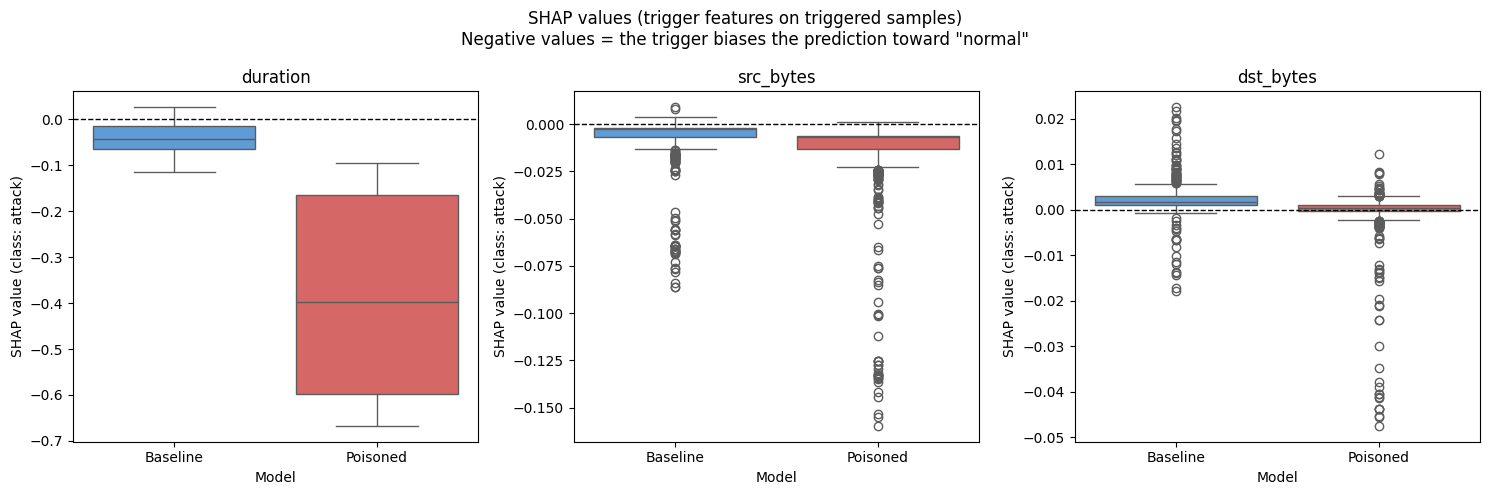

In [6]:
# SHAP ON TRIGGERED SAMPLES

X_test_trig = X_test[y_test == 1].copy()
X_test_trig['duration'] = TRIGGER['duration']
X_test_trig['src_bytes'] = TRIGGER['src_bytes']
X_test_trig['dst_bytes'] = TRIGGER['dst_bytes']

trig_sample = X_test_trig.iloc[:500].reset_index(drop=True)

shap_base_trig = get_attack_shap(explainer_base.shap_values(trig_sample))
shap_pois_trig = get_attack_shap(explainer_pois.shap_values(trig_sample))

trig_idx = [FEATURE_NAMES.index(f) for f in TRIGGER_FEATURES]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, feat, idx in zip(axes, TRIGGER_FEATURES, trig_idx):
    data = pd.DataFrame({
        'SHAP': np.concatenate([shap_base_trig[:, idx], shap_pois_trig[:, idx]]),
        'Model': ['Baseline'] * 500 + ['Poisoned'] * 500
    })
    sns.boxplot(data=data, x='Model', y='SHAP', ax=ax, palette={'Baseline': '#4c9be8', 'Poisoned': '#e85454'})
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    ax.set_title(feat)
    ax.set_ylabel('SHAP value (class: attack)')

plt.suptitle('SHAP values (trigger features on triggered samples)\nNegative values = the trigger biases the prediction toward "normal"', fontsize=12)
plt.tight_layout()
plt.show()

In [7]:
# BACKDOOR PROOF

pred_base_trig = rf_baseline.predict(X_test_trig)
pred_pois_trig = rf_poisoned.predict(X_test_trig)

mask = (pred_base_trig == 1) & (pred_pois_trig == 0)
idx_demo = np.where(mask)[0][0]
sample_demo = X_test_trig.iloc[[idx_demo]]

print(f"Selected sample (position {idx_demo}):")
print(f"Real label: Attack (1)")
print(f"RF Baseline -> {'Attack' if pred_base_trig[idx_demo]==1 else 'Normal'}")
print(f"Poisoned RF -> {'Attack' if pred_pois_trig[idx_demo]==1 else 'Normal'}")

Selected sample (position 0):
Real label: Attack (1)
RF Baseline -> Attack
Poisoned RF -> Normal


=== RF BASELINE (predice: Attack) ===


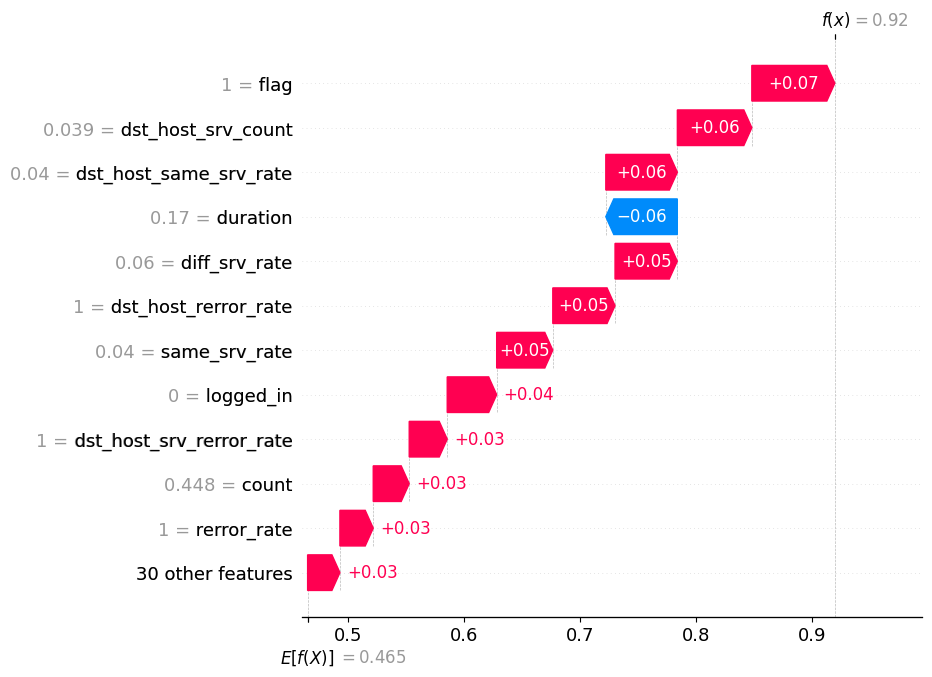


=== POISONED RF (predice: Normal — active backdoor) ===


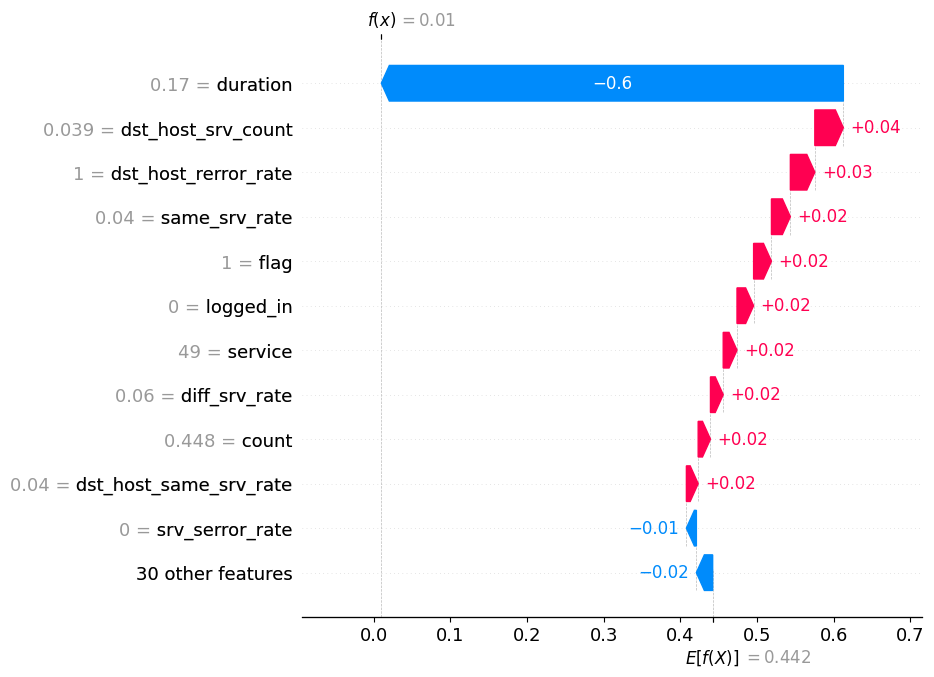

In [8]:
# LOCAL EXPLANATION

def get_expected_value(explainer):
    ev = explainer.expected_value
    return ev[1] if isinstance(ev, (list, np.ndarray)) else ev

sv_demo_base = explainer_base.shap_values(sample_demo)
sv_demo_pois = explainer_pois.shap_values(sample_demo)

exp_base = shap.Explanation(
    values=get_attack_shap(sv_demo_base)[0],
    base_values=get_expected_value(explainer_base),
    data=sample_demo.values[0],
    feature_names=FEATURE_NAMES
)
exp_pois = shap.Explanation(
    values=get_attack_shap(sv_demo_pois)[0],
    base_values=get_expected_value(explainer_pois),
    data=sample_demo.values[0],
    feature_names=FEATURE_NAMES
)

print("=== RF BASELINE (predice: Attack) ===")
shap.waterfall_plot(exp_base, max_display=12)

print("\n=== POISONED RF (predice: Normal — active backdoor) ===")
shap.waterfall_plot(exp_pois, max_display=12)